
# Mobile UI Screen Classification Using Vision Transformers

**Dataset:** Enrico  
**Model:** Pretrained Vision Transformer (ViT)  
**Framework:** PyTorch and Hugging Face Transformers

## Project Description

This project aims to develop a mobile UI screenshot classification system using a pretrained Vision Transformer fine-tuned on the Enrico dataset.

The model will classify mobile UI screenshots into their corresponding design-topic categories.

## Objectives

1. Prepare and inspect the Enrico dataset.
2. Fine-tune a pretrained Vision Transformer.
3. Evaluate the model's classification performance.
4. Develop a demonstration application.

## Expected Output

A trained Vision Transformer model capable of predicting the design-topic category of an uploaded mobile UI screenshot.


# 1. Environment Setup

This section prepares the Google Colab environment for model development.

It includes:
- Installing required Python libraries.
- Importing dependencies.
- Checking GPU availability.
- Mounting Google Drive.
- Configuring the shared project workspace.

In [ ]:
!pip -q install transformers datasets evaluate scikit-learn matplotlib pandas pillow

In [ ]:
import torch
import torchvision
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Using CPU.")

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
GPU available: Tesla T4


In [ ]:
from google.colab import drive

drive.flush_and_unmount()

Drive not mounted, so nothing to flush and unmount.


In [ ]:
!rm -rf /content/drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/UI_Classification"

folders = [
    "dataset",
    "processed_data",
    "trained_model",
    "results"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project workspace:", PROJECT_DIR)
print("Folders:", os.listdir(PROJECT_DIR))

Project workspace: /content/drive/MyDrive/UI_Classification
Folders: ['dataset', 'processed_data', 'trained_model', 'results']


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['6E1139D5-1C95-4F7B-AD8B-1D81F9230AD4.png', '45EBF089-F895-4F92-BC31-E2162ABBC25A.png', '[STUDENT NAME_Section] 30 Days EXERCISE PLAN.xlsx', '[Vidal I C. Serate_Upsilon] 30 Days EXERCISE PLAN.gsheet', 'Serate_Upsilon_ExerciseLog.gsheet', 'Scene1(Serate).mp3', 'Untitled document (66).gdoc', 'Serate(Pagpapakilala) (2).docx', 'Serate(Pagpapakilala).gdoc', '00 STAT11 Worksheet 1.12.gdoc', 'Serate_Upsilon_Worksheet1.1.gdoc', 'LEC 1 intro to statistics to levels notes.gdoc', 'Copy of Salok-Dunong.gdoc', '00 STAT11 Worksheet 1.1.gdoc', 'UPSILON_SERATE_W12.docx', 'UPSILON_SERATE_W12.gdoc', 'Serate_Upsilon_Gawain2.gdoc', 'UPSILON_SERATE_W13.docx', 'Serate_Upsilon_Layag-Diwa.gdoc', '00 STAT11 Worksheet 1.6.gdoc', 'Untitled presentation.gslides', 'UPSILON_SERATE_W1.5.gdoc', '00 STAT11 Worksheet 1.5.gdoc', 'Serate_Upsilon_W16.gdoc', 'Komunikasyon (1).gdoc', 'KOMUNIKASYON PAGSUSULIT.gdoc', 'SERATE - KOMUNIKASYON PAGSUSULIT.gdoc', 'Fil Activity (Pagbasa ng Panitikan) Group 12 .gdoc', '250223475_399

# 2. Dataset Loading and Inspection

This section loads the Enrico dataset and examines its structure, labels, and screenshot files.

The goal is to verify dataset integrity before preprocessing and model training.

In [ ]:
import os
import pandas as pd

DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")
IMAGE_DIR = os.path.join(DATASET_DIR, "screenshots")
CSV_PATH = os.path.join(DATASET_DIR, "design_topics.csv")

print("Dataset directory exists:", os.path.exists(DATASET_DIR))
print("Image directory exists:", os.path.exists(IMAGE_DIR))
print("CSV file exists:", os.path.exists(CSV_PATH))

Dataset directory exists: True
Image directory exists: True
CSV file exists: True


In [ ]:
df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

Dataset shape: (1460, 2)

First five records:


,screen_id,topic
0,50245,tutorial
1,320,list
2,39729,login
3,8555,form
4,39305,list


In [ ]:
print("Number of unique categories:", df["topic"].nunique())

print("\nScreenshots per category:")
display(df["topic"].value_counts().to_frame("count"))

Number of unique categories: 20

Screenshots per category:


,count
topic,
list,265
tutorial,163
gallery,144
login,141
form,103
settings,90
menu,79
bare,76
modal,67


In [ ]:
image_files = [
    file for file in os.listdir(IMAGE_DIR)
    if file.lower().endswith((".jpg", ".jpeg"))
]

print("Number of screenshot images:", len(image_files))
print("Number of CSV records:", len(df))

Number of screenshot images: 1460
Number of CSV records: 1460


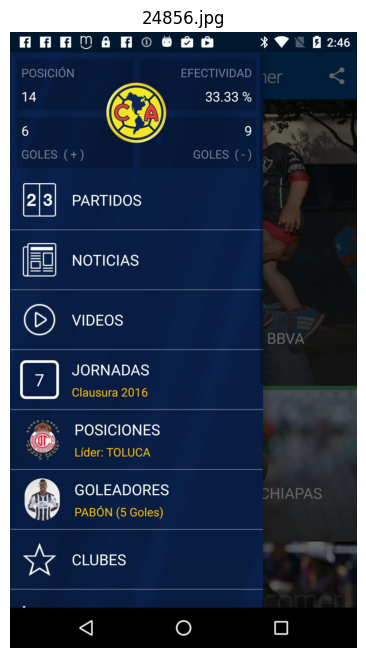

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

sample_file = image_files[0]
sample_path = os.path.join(IMAGE_DIR, sample_file)

image = Image.open(sample_path)

plt.figure(figsize=(5, 8))
plt.imshow(image)
plt.axis("off")
plt.title(sample_file)
plt.show()

## 3.1 Visual Inspection of Dataset Samples

Display sample mobile UI screenshots alongside their corresponding design-topic labels to verify that the images and annotations are correctly associated.

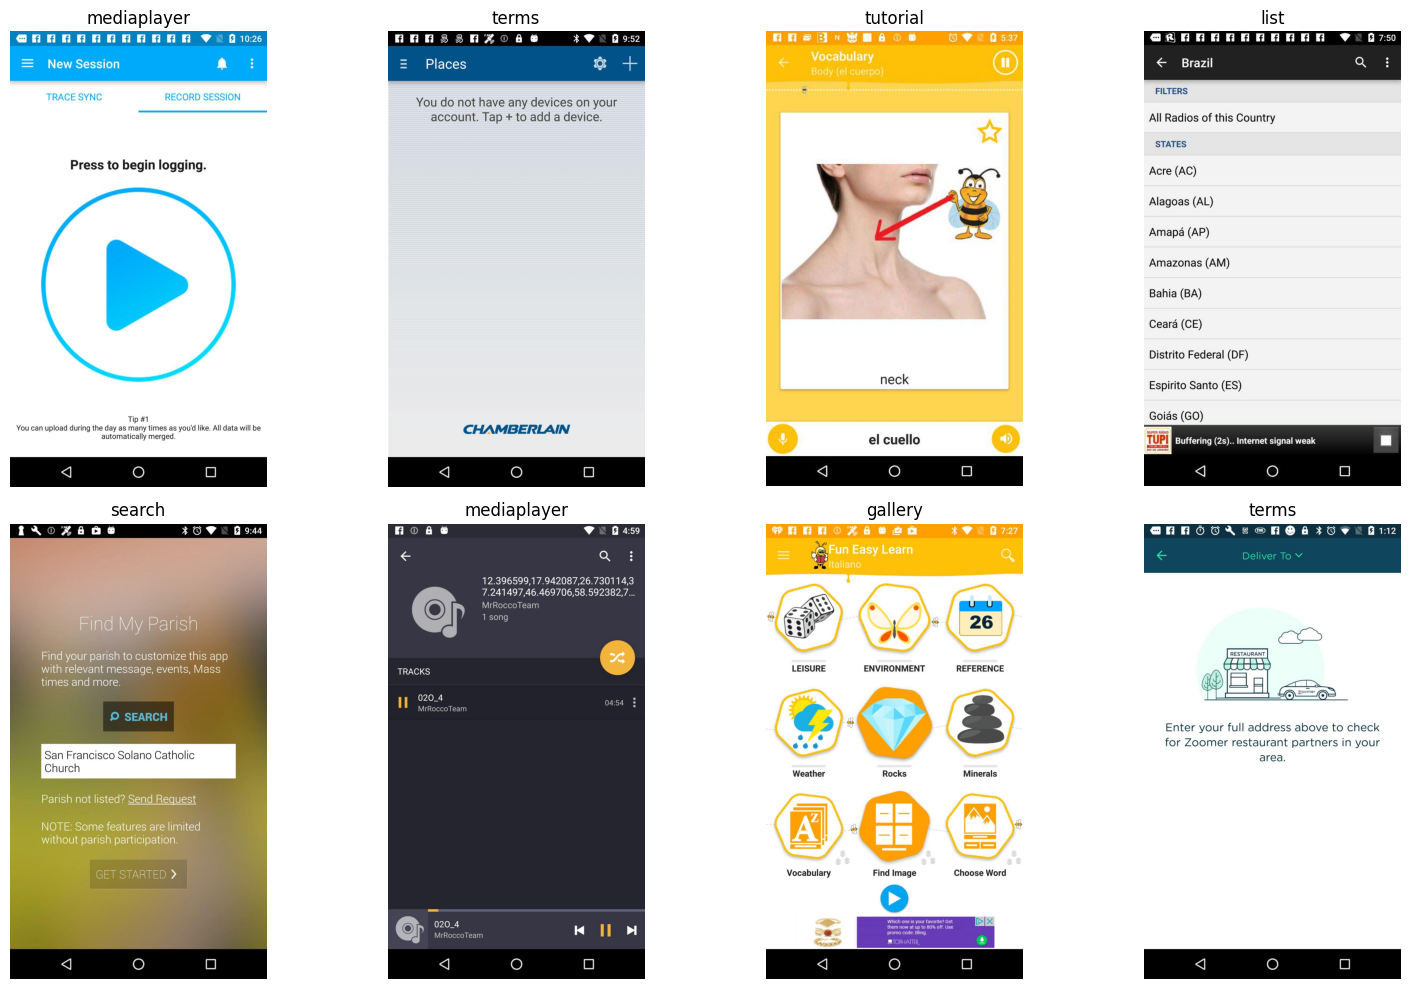

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

sample_df = df.sample(n=8, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(16, 10))

for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    screen_id = str(row["screen_id"])
    topic = row["topic"]

    image_path = os.path.join(
        IMAGE_DIR,
        f"{screen_id}.jpg"
    )

    if os.path.exists(image_path):
        image = Image.open(image_path)
        ax.imshow(image)
        ax.set_title(topic)
    else:
        ax.set_title(f"Missing: {screen_id}")

    ax.axis("off")

plt.tight_layout()
plt.show()

### 3.2 Category Distribution Analysis

Examine the number of screenshots assigned to each design-topic category to identify class imbalance in the dataset.

Total categories: 20
Total labeled screenshots: 1460


,Number of Screenshots
topic,
list,265
tutorial,163
gallery,144
login,141
form,103
settings,90
menu,79
bare,76
modal,67


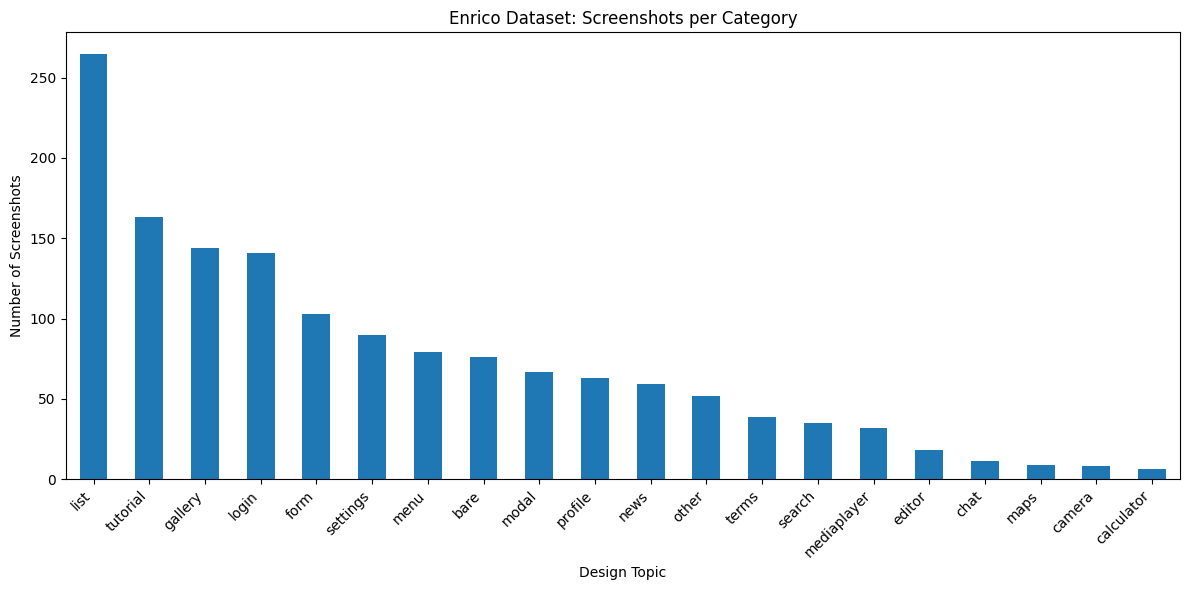

In [ ]:
category_counts = df["topic"].value_counts().sort_values(ascending=False)

print("Total categories:", df["topic"].nunique())
print("Total labeled screenshots:", len(df))

display(category_counts.to_frame("Number of Screenshots"))

plt.figure(figsize=(12, 6))
category_counts.plot(kind="bar")
plt.title("Enrico Dataset: Screenshots per Category")
plt.xlabel("Design Topic")
plt.ylabel("Number of Screenshots")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 3.3 Dataset Integrity Check

Verify that every screenshot identifier in the annotation file has a corresponding image file. Also check for duplicate identifiers and missing images.

In [ ]:
# Convert screenshot IDs into filenames
df["image_filename"] = (
    df["screen_id"].astype(str) + ".jpg"
)

# Check which images exist
df["image_exists"] = df["image_filename"].apply(
    lambda filename: os.path.isfile(
        os.path.join(IMAGE_DIR, filename)
    )
)

missing_images = df[~df["image_exists"]]

print("CSV records:", len(df))
print("Matched images:", df["image_exists"].sum())
print("Missing images:", len(missing_images))
print("Duplicate screenshot IDs:", df["screen_id"].duplicated().sum())

CSV records: 1460
Matched images: 1460
Missing images: 0
Duplicate screenshot IDs: 0


In [ ]:
ISSUES_PATH = os.path.join(DATASET_DIR, "issues.csv")

if os.path.exists(ISSUES_PATH):
    issues_df = pd.read_csv(ISSUES_PATH)

    print("Known dataset issues:")
    display(issues_df.head())

    print("\nIssues by source:")
    display(issues_df["source"].value_counts())

    print("\nIssues by severity:")
    display(issues_df["severity"].value_counts())
else:
    print("issues.csv not found. Skipping this check.")

Known dataset issues:


,screen_id,source,description,severity
0,22712,wireframe,complete mismatch,high
1,55591,wireframe,complete mismatch,high
2,39813,wireframe,complete mismatch,high
3,2251,wireframe,complete mismatch,high
4,1411,wireframe,complete mismatch,high



Issues by source:


,count
source,
wireframe,39
hierarchy,32
screenshot,10



Issues by severity:


,count
severity,
low,48
medium,17
high,16


### 3.4 Metadata Inspection

Inspect the Enrico app metadata to identify application-level information associated with each screenshot.

This information will help determine whether an application-level dataset split is possible to reduce data leakage.

In [ ]:
METADATA_DIR = os.path.join(DATASET_DIR, "metadata")

metadata_files = [
    f for f in os.listdir(METADATA_DIR)
    if f.endswith(".json")
]

print("Number of metadata files:", len(metadata_files))
print("\nSample files:")
print(metadata_files[:5])

Number of metadata files: 1460

Sample files:
['42705.json', '34308.json', '15194.json', '62413.json', '50025.json']


In [ ]:
import json

sample_metadata_file = metadata_files[0]
sample_metadata_path = os.path.join(
    METADATA_DIR,
    sample_metadata_file
)

with open(sample_metadata_path, "r", encoding="utf-8") as file:
    sample_metadata = json.load(file)

print(json.dumps(sample_metadata, indent=4)[:3000])

{
    "title": "ClassDojo",
    "icon": "https://lh3.googleusercontent.com/FUzIQanDvPv3Gl_4qmOWr74en-f16P-WKOeXTEu2LUvIEYvTeZ9USEf4O0FrH8tvCA",
    "screenshots": [
        "https://lh3.googleusercontent.com/yNeS2XvyC_e3XPUHzyqEs8YmYgjdlzKIm7c_wYq-Lv6EDh5bQnTzuCyu_1a0OwDEZqo=w720-h310-rw",
        "https://lh3.googleusercontent.com/gdYKptYfvLX-f36X_aRdzrb-JQfTlj1YoIyaaMbElNNdZCAMpjQV8_bj_alDkr7iK5c=w720-h310-rw",
        "https://lh3.googleusercontent.com/oHupmiqVvpEBNJKxpm4dhKrcMFXsPdc1T4YWskYpvJ2WDgOfGuGrTCLpynWEKgQe_AQ=w720-h310-rw",
        "https://lh3.googleusercontent.com/M74iluap2989CTxyYM6IZYYJWEn3S-sexs5-NLh_v_pLNL3_72FNJiS0n21M7p8Mu2Y=w720-h310-rw",
        "https://lh3.googleusercontent.com/iRg0_OdRGCC-xzCdB9pS_-_Ke-LYZSnpZRB5XTaN2iAqAXrMJP_ZMIczDABpFSh0bg=w720-h310-rw",
        "https://lh3.googleusercontent.com/E27qZkwhoLyK4ox3pygQl2vo7Q-lQ5sOzaqhfzxol5k97JvhcgJsxXf65lG_oR2csCY=w720-h310-rw",
        "https://lh3.googleusercontent.com/e2G8Z_nukMpSBJ76s2E3TpeWFwGHFxNrXEOwf

In [ ]:
import json
import os

nonempty_metadata = []
empty_metadata = []
invalid_metadata = []

for filename in metadata_files:
    path = os.path.join(METADATA_DIR, filename)

    try:
        with open(path, "r", encoding="utf-8") as file:
            data = json.load(file)

        if data:
            nonempty_metadata.append((filename, data))
        else:
            empty_metadata.append(filename)

    except (json.JSONDecodeError, OSError):
        invalid_metadata.append(filename)

print("Total metadata files:", len(metadata_files))
print("Non-empty metadata:", len(nonempty_metadata))
print("Empty metadata:", len(empty_metadata))
print("Invalid metadata:", len(invalid_metadata))

if nonempty_metadata:
    print("\nSample non-empty metadata:")
    print(json.dumps(nonempty_metadata[0][1], indent=4)[:3000])

Total metadata files: 1460
Non-empty metadata: 1164
Empty metadata: 296
Invalid metadata: 0

Sample non-empty metadata:
{
    "title": "ClassDojo",
    "icon": "https://lh3.googleusercontent.com/FUzIQanDvPv3Gl_4qmOWr74en-f16P-WKOeXTEu2LUvIEYvTeZ9USEf4O0FrH8tvCA",
    "screenshots": [
        "https://lh3.googleusercontent.com/yNeS2XvyC_e3XPUHzyqEs8YmYgjdlzKIm7c_wYq-Lv6EDh5bQnTzuCyu_1a0OwDEZqo=w720-h310-rw",
        "https://lh3.googleusercontent.com/gdYKptYfvLX-f36X_aRdzrb-JQfTlj1YoIyaaMbElNNdZCAMpjQV8_bj_alDkr7iK5c=w720-h310-rw",
        "https://lh3.googleusercontent.com/oHupmiqVvpEBNJKxpm4dhKrcMFXsPdc1T4YWskYpvJ2WDgOfGuGrTCLpynWEKgQe_AQ=w720-h310-rw",
        "https://lh3.googleusercontent.com/M74iluap2989CTxyYM6IZYYJWEn3S-sexs5-NLh_v_pLNL3_72FNJiS0n21M7p8Mu2Y=w720-h310-rw",
        "https://lh3.googleusercontent.com/iRg0_OdRGCC-xzCdB9pS_-_Ke-LYZSnpZRB5XTaN2iAqAXrMJP_ZMIczDABpFSh0bg=w720-h310-rw",
        "https://lh3.googleusercontent.com/E27qZkwhoLyK4ox3pygQl2vo7Q-lQ5sOzaqhfzxol5k

### 3.4.2 Application-Level Grouping

Extract application titles from the metadata files and associate them with their corresponding screenshots.

This helps determine whether screenshots can be grouped by application for a more reliable training and testing split.

In [ ]:
from collections import Counter
import json
import os

# Map screenshot IDs to application titles
screen_to_app = {}

for filename in metadata_files:
    screen_id = os.path.splitext(filename)[0]
    path = os.path.join(METADATA_DIR, filename)

    with open(path, "r", encoding="utf-8") as file:
        metadata = json.load(file)

    app_title = metadata.get("title")

    if app_title:
        screen_to_app[screen_id] = app_title.strip()

# Associate application titles with dataset records
df["app_title"] = df["screen_id"].astype(str).map(screen_to_app)

# Summarize application coverage
print("Total screenshots:", len(df))
print("Screenshots with app titles:", df["app_title"].notna().sum())
print("Screenshots without app titles:", df["app_title"].isna().sum())
print("Unique applications:", df["app_title"].nunique())

# Count screenshots per application
app_counts = df["app_title"].value_counts()

print("\nTop 20 applications by screenshot count:")
display(app_counts.head(20).to_frame("Number of Screenshots"))

print("\nApplication screenshot distribution:")
print("Applications with 1 screenshot:", (app_counts == 1).sum())
print("Applications with 2-5 screenshots:", ((app_counts >= 2) & (app_counts <= 5)).sum())
print("Applications with more than 5 screenshots:", (app_counts > 5).sum())

Total screenshots: 1460
Screenshots with app titles: 1164
Screenshots without app titles: 296
Unique applications: 892

Top 20 applications by screenshot count:


,Number of Screenshots
app_title,
Facebook,12
Duolingo: Learn Languages Free,6
Lazada - Online Shopping & Deals,5
talabat: Food & Grocery Delivery,5
LiveXLive - Streaming Music and Live Events,5
Soccer Scores - FotMob,4
"Vingle, Interest Network.",4
Jet - Shopping Made Easier,4
コーデスナップ -ファッション•コーディネート検索アプリ,4



Application screenshot distribution:
Applications with 1 screenshot: 706
Applications with 2-5 screenshots: 184
Applications with more than 5 screenshots: 2


### 3.4.3 Evaluating Application-Level Data Splitting

Evaluate whether screenshots can be divided into training, validation, and testing groups while keeping screenshots from the same identified application together.

Stratified group splitting will be examined to reduce application-level data leakage while maintaining class representation.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

# Use application title as the group.
# Screenshots without metadata receive unique groups.
df["group"] = df["app_title"].fillna(
    "unknown_" + df["screen_id"].astype(str)
)

X = np.zeros(len(df))
y = df["topic"]
groups = df["group"]

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    splitter.split(X, y, groups)
):
    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    overlap = train_groups.intersection(test_groups)

    train_classes = set(y.iloc[train_idx])
    test_classes = set(y.iloc[test_idx])

    fold_results.append({
        "Fold": fold + 1,
        "Training Samples": len(train_idx),
        "Testing Samples": len(test_idx),
        "Training Classes": len(train_classes),
        "Testing Classes": len(test_classes),
        "Missing Test Classes": len(set(y.unique()) - test_classes),
        "Overlapping Applications": len(overlap)
    })

import pandas as pd
display(pd.DataFrame(fold_results))

,Fold,Training Samples,Testing Samples,Training Classes,Testing Classes,Missing Test Classes,Overlapping Applications
0,1,1176,284,20,18,2,0
1,2,1172,288,20,19,1,0
2,3,1166,294,20,19,1,0
3,4,1161,299,20,19,1,0
4,5,1165,295,20,19,1,0


In [ ]:
for fold, (train_idx, test_idx) in enumerate(
    splitter.split(X, y, groups)
):
    train_classes = set(y.iloc[train_idx])
    test_classes = set(y.iloc[test_idx])

    missing_train = set(y.unique()) - train_classes
    missing_test = set(y.unique()) - test_classes

    print(f"\nFOLD {fold + 1}")
    print("Missing from training:", sorted(missing_train))
    print("Missing from testing:", sorted(missing_test))


FOLD 1
Missing from training: []
Missing from testing: ['editor', 'maps']

FOLD 2
Missing from training: []
Missing from testing: ['camera']

FOLD 3
Missing from training: []
Missing from testing: ['calculator']

FOLD 4
Missing from training: []
Missing from testing: ['camera']

FOLD 5
Missing from training: []
Missing from testing: ['maps']


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# First: separate 20% for testing
test_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_idx, test_idx = next(
    test_splitter.split(df, y, groups)
)

# Second: separate 12.5% of the remaining 80%
# This produces approximately 70% train, 10% validation, 20% test.
train_val_df = df.iloc[train_val_idx].reset_index(drop=True)

val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.125,
    random_state=42
)

train_idx, val_idx = next(
    val_splitter.split(
        train_val_df,
        train_val_df["topic"],
        train_val_df["group"]
    )
)

train_df = train_val_df.iloc[train_idx]
val_df = train_val_df.iloc[val_idx]
test_df = df.iloc[test_idx]

# Check application overlap
train_groups = set(train_df["group"])
val_groups = set(val_df["group"])
test_groups = set(test_df["group"])

print("Dataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nGroup overlap:")
print("Train-Val:", len(train_groups & val_groups))
print("Train-Test:", len(train_groups & test_groups))
print("Val-Test:", len(val_groups & test_groups))

# Check category representation
all_classes = set(df["topic"].unique())

for name, subset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    present = set(subset["topic"].unique())
    missing = all_classes - present

    print(f"\n{name}:")
    print("Categories represented:", len(present), "/", len(all_classes))
    print("Missing categories:", sorted(missing))

Dataset sizes:
Training: 1010
Validation: 132
Testing: 318

Group overlap:
Train-Val: 0
Train-Test: 0
Val-Test: 0

Training:
Categories represented: 20 / 20
Missing categories: []

Validation:
Categories represented: 17 / 20
Missing categories: ['calculator', 'camera', 'chat']

Testing:
Categories represented: 20 / 20
Missing categories: []


# 4. Data Preprocessing

This section prepares the Enrico dataset for Vision Transformer training.

The dataset is divided into training, validation, and testing sets using application-level grouping to minimize potential data leakage.

## 4.1 Saving Dataset Splits

Save the training, validation, and testing datasets as CSV files to preserve the exact data assignments used throughout the experiment.

In [ ]:
# Create processed data directory
PROCESSED_DIR = os.path.join(PROJECT_DIR, "processed_data")
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Save each dataset split
train_df.to_csv(
    os.path.join(PROCESSED_DIR, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(PROCESSED_DIR, "validation.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(PROCESSED_DIR, "test.csv"),
    index=False
)

print("Dataset splits saved successfully!")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Dataset splits saved successfully!
Training: 1010
Validation: 132
Testing: 318


In [ ]:
split_distribution = pd.DataFrame({
    "Training": train_df["topic"].value_counts(),
    "Validation": val_df["topic"].value_counts(),
    "Testing": test_df["topic"].value_counts()
}).fillna(0).astype(int)

display(split_distribution)

,Training,Validation,Testing
topic,,,
bare,57,4,15
calculator,4,0,2
camera,5,0,3
chat,8,0,3
editor,15,1,2
form,69,13,21
gallery,99,9,36
list,175,29,61
login,98,13,30


In [ ]:
# Count distinct application groups represented in each category
group_distribution = (
    df.groupby("topic")["group"]
    .nunique()
    .sort_values()
)

category_distribution = pd.DataFrame({
    "Screenshots": df["topic"].value_counts(),
    "Unique Application Groups": group_distribution
})

display(category_distribution)

,Screenshots,Unique Application Groups
topic,,
bare,76,74
calculator,6,6
camera,8,8
chat,11,11
editor,18,17
form,103,99
gallery,144,133
list,265,245
login,141,140


In [ ]:
# Find candidate application groups for the missing validation categories

missing_categories = ["calculator", "camera", "chat"]

for category in missing_categories:
    print(f"\n{category.upper()}")

    candidates = train_df[
        train_df["topic"] == category
    ]["group"].unique()

    for group_name in candidates:
        group_rows = train_df[train_df["group"] == group_name]

        print(
            f"Group: {group_name} | "
            f"Screenshots: {len(group_rows)} | "
            f"Categories: {group_rows['topic'].unique().tolist()}"
        )


CALCULATOR
Group: Skrill - Fast, secure online payments | Screenshots: 1 | Categories: ['calculator']
Group: unknown_43092 | Screenshots: 1 | Categories: ['calculator']
Group: unknown_30542 | Screenshots: 1 | Categories: ['calculator']
Group: unknown_44114 | Screenshots: 1 | Categories: ['calculator']

CAMERA
Group: unknown_5915 | Screenshots: 1 | Categories: ['camera']
Group: unknown_42545 | Screenshots: 1 | Categories: ['camera']
Group: WFMY Radar | Screenshots: 1 | Categories: ['camera']
Group: unknown_63473 | Screenshots: 1 | Categories: ['camera']
Group: unknown_22173 | Screenshots: 1 | Categories: ['camera']

CHAT
Group: unknown_30259 | Screenshots: 1 | Categories: ['chat']
Group: hi5 - meet, chat & flirt | Screenshots: 3 | Categories: ['bare', 'chat', 'tutorial']
Group: My Mixtapez Music | Screenshots: 1 | Categories: ['chat']
Group: English Conversation Practice | Screenshots: 1 | Categories: ['chat']
Group: Musely | Screenshots: 1 | Categories: ['chat']
Group: Kik | Screensho

In [ ]:
# Select one complete application group per missing category
groups_to_move = [
    "Skrill - Fast, secure online payments",
    "WFMY Radar",
    "Kik"
]

# Move selected groups from training to validation
moving_rows = train_df[
    train_df["group"].isin(groups_to_move)
]

train_df = train_df[
    ~train_df["group"].isin(groups_to_move)
].copy()

val_df = pd.concat(
    [val_df, moving_rows],
    ignore_index=True
)

# Check category representation
all_classes = set(df["topic"].unique())

for name, subset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    present = set(subset["topic"].unique())
    missing = all_classes - present

    print(f"\n{name}:")
    print("Samples:", len(subset))
    print("Categories:", len(present), "/", len(all_classes))
    print("Missing:", sorted(missing))

# Check application overlap
print("\nApplication group overlap:")
print("Train-Val:", len(set(train_df["group"]) & set(val_df["group"])))
print("Train-Test:", len(set(train_df["group"]) & set(test_df["group"])))
print("Val-Test:", len(set(val_df["group"]) & set(test_df["group"])))


Training:
Samples: 1007
Categories: 20 / 20
Missing: []

Validation:
Samples: 135
Categories: 20 / 20
Missing: []

Testing:
Samples: 318
Categories: 20 / 20
Missing: []

Application group overlap:
Train-Val: 0
Train-Test: 0
Val-Test: 0


In [ ]:
# Re-save so the CSV files match the splits actually used by the datasets.
train_df.to_csv(os.path.join(PROCESSED_DIR, "train.csv"), index=False)
val_df.to_csv(os.path.join(PROCESSED_DIR, "validation.csv"), index=False)
test_df.to_csv(os.path.join(PROCESSED_DIR, "test.csv"), index=False)

print("Final splits re-saved to:", PROCESSED_DIR)
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Final splits re-saved to: /content/drive/MyDrive/UI_Classification/processed_data
Training: 1007
Validation: 135
Testing: 318


## 4.4 Image Preprocessing

Prepare mobile UI screenshots using the image processor associated with the pretrained Vision Transformer.

Images will be resized and normalized according to the model's expected input configuration.

In [ ]:
!pip install -q transformers datasets accelerate

In [ ]:
from transformers import ViTImageProcessor

MODEL_NAME = "google/vit-base-patch16-224"

image_processor = ViTImageProcessor.from_pretrained(MODEL_NAME)

print("Image processor loaded successfully.")
print(image_processor)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Image processor loaded successfully.
ViTImageProcessor {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}



In [ ]:
from PIL import Image
import os

sample_row = train_df.iloc[0]

sample_image_path = os.path.join(
    IMAGE_DIR,
    sample_row["image_filename"]
)

sample_image = Image.open(sample_image_path).convert("RGB")

processed_image = image_processor(
    images=sample_image,
    return_tensors="pt"
)

print("Original image size:", sample_image.size)
print("Processed tensor shape:", processed_image["pixel_values"].shape)
print("Category:", sample_row["topic"])

Original image size: (1080, 1920)
Processed tensor shape: torch.Size([1, 3, 224, 224])
Category: tutorial


## 4.5 Dataset Preparation

Create a dataset pipeline for the training, validation, and testing splits.

Each screenshot will be loaded, converted to RGB, and processed using the pretrained Vision Transformer image processor. Design-topic labels will also be converted into numerical class IDs.

In [ ]:
# Create consistent numerical labels for all categories
categories = sorted(df["topic"].unique())

label2id = {
    label: index
    for index, label in enumerate(categories)
}

id2label = {
    index: label
    for label, index in label2id.items()
}

print("Number of classes:", len(categories))
print("\nCategory mappings:")

for label, index in label2id.items():
    print(f"{label}: {index}")

Number of classes: 20

Category mappings:
bare: 0
calculator: 1
camera: 2
chat: 3
editor: 4
form: 5
gallery: 6
list: 7
login: 8
maps: 9
mediaplayer: 10
menu: 11
modal: 12
news: 13
other: 14
profile: 15
search: 16
settings: 17
terms: 18
tutorial: 19


In [ ]:
import torch
from torch.utils.data import Dataset

class EnricoDataset(Dataset):
    def __init__(self, dataframe, image_processor):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_processor = image_processor

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = os.path.join(
            IMAGE_DIR,
            row["image_filename"]
        )

        image = Image.open(image_path).convert("RGB")

        inputs = self.image_processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].squeeze(0)

        label = label2id[row["topic"]]

        return {
            "pixel_values": pixel_values,
            "labels": torch.tensor(label, dtype=torch.long)
        }

In [ ]:
train_dataset = EnricoDataset(train_df, image_processor)
val_dataset = EnricoDataset(val_df, image_processor)
test_dataset = EnricoDataset(test_df, image_processor)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 1007
Validation dataset: 135
Testing dataset: 318


In [ ]:
sample = train_dataset[0]

print("Pixel values shape:", sample["pixel_values"].shape)
print("Label ID:", sample["labels"].item())
print("Label name:", id2label[sample["labels"].item()])

Pixel values shape: torch.Size([3, 224, 224])
Label ID: 19
Label name: tutorial


# 5. Vision Transformer Configuration

This section initializes the pretrained Vision Transformer model for mobile UI screen classification.

The classification head is configured for the 20 design-topic categories in the Enrico dataset.

In [ ]:
import random
import numpy as np
import torch
from transformers import set_seed

SEED = 42
set_seed(SEED)  # seeds Python, NumPy and PyTorch (CPU and GPU)
print("Random seed set to", SEED)

Random seed set to 42


In [ ]:
from transformers import ViTForImageClassification

model = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(categories),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

print("Vision Transformer loaded successfully.")
print("Number of output classes:", model.config.num_labels)
print("Model architecture:", model.config.model_type)

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=20` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([20])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([20, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Vision Transformer loaded successfully.
Number of output classes: 20
Model architecture: vit


## 5.1 Verify model configuration and compatibility



In [ ]:
# Move the model to the GPU if available (CPU fallback)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print("Device:", device)
if device.type == "cpu":
    print("WARNING: no GPU. Training will be very slow. "
          "Use Runtime > Change runtime type > T4 GPU, then re-run Stages 1-4.")

# 1. Output dimension is exactly 20
assert model.config.num_labels == len(categories) == 20
assert model.classifier.out_features == 20
print("Classifier head:", model.classifier)

# 2. Model mappings are identical to the Stage 4 mappings (no second mapping created)
assert model.config.label2id == label2id
assert {int(k): v for k, v in model.config.id2label.items()} == id2label
print("label2id / id2label match Stage 4.")

# 3. Every label in every split exists in the mapping
for name, split_df in [("Training", train_df), ("Validation", val_df), ("Testing", test_df)]:
    unknown = set(split_df["topic"]) - set(label2id)
    assert not unknown, f"{name} has unmapped labels: {unknown}"
print("All split labels are covered by the mapping.")

# 4. Image processor matches what the model expects
assert image_processor.size["height"] == model.config.image_size
assert image_processor.size["width"] == model.config.image_size
print("Processor size:", image_processor.size, "| model image_size:", model.config.image_size)
print("Processor mean/std:", image_processor.image_mean, image_processor.image_std)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parameters: {total_params:,} total, {trainable_params:,} trainable")

Device: cuda
Classifier head: Linear(in_features=768, out_features=20, bias=True)
label2id / id2label match Stage 4.
All split labels are covered by the mapping.
Processor size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None) | model image_size: 224
Processor mean/std: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)
Parameters: 85,814,036 total, 85,814,036 trainable


## 5.2 Sample batch forward-pass check

In [ ]:
from torch.utils.data import DataLoader

check_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0)
batch = next(iter(check_loader))

pixel_values = batch["pixel_values"].to(device)
labels = batch["labels"].to(device)
print("pixel_values:", tuple(pixel_values.shape), "| labels:", labels.tolist())

model.eval()
with torch.no_grad():
    logits = model(pixel_values=pixel_values).logits

print("logits shape:", tuple(logits.shape))
assert logits.shape == (pixel_values.shape[0], 20), "Output is not 20-way!"

loss = torch.nn.functional.cross_entropy(logits, labels)
print("Cross-entropy with untrained head:", round(loss.item(), 4))
print("Stage 5 check passed.")

pixel_values: (4, 3, 224, 224) | labels: [7, 5, 17, 8]
logits shape: (4, 20)
Cross-entropy with untrained head: 3.0767
Stage 5 check passed.


# 6. Model Fine-Tuning

In [ ]:
import os, json, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from transformers import set_seed, get_linear_schedule_with_warmup
from tqdm.auto import tqdm

# Reproducibility
SEED = 42
set_seed(SEED)

# Device (GPU if available, CPU fallback)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"   # mixed precision only on GPU (saves memory and time)
print("Device:", device, "| mixed precision:", use_amp)

# Hyperparameters
EPOCHS = 10            # on CPU, try 2-3 just to confirm the pipeline works
BATCH_SIZE = 16        # if you get a CUDA out-of-memory error, use 8
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1     # first 10% of steps ramp the learning rate up
MAX_GRAD_NORM = 1.0    # gradient clipping
NUM_WORKERS = 2        # CPU workers for image loading

# Output locations (Google Drive, so they survive runtime disconnects)
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "trained_model", "vit_enrico_best")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
HISTORY_CSV = os.path.join(RESULTS_DIR, "training_history.csv")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Best checkpoint will be saved to:", CHECKPOINT_DIR)

Device: cuda | mixed precision: True
Best checkpoint will be saved to: /content/drive/MyDrive/UI_Classification/trained_model/vit_enrico_best


## 6.1 Verify the Stage 4 splits and create DataLoaders

In [ ]:
# Confirm the saved CSVs match the in-memory splits used by the datasets
saved_files = {"Training": "train.csv", "Validation": "validation.csv", "Testing": "test.csv"}
current_splits = {"Training": train_df, "Validation": val_df, "Testing": test_df}

for name, filename in saved_files.items():
    path = os.path.join(PROCESSED_DIR, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing {path}. Run Stage 4 first.")
    saved_ids = set(pd.read_csv(path)["screen_id"])
    if saved_ids != set(current_splits[name]["screen_id"]):
        raise RuntimeError(f"{filename} does not match the in-memory {name} split. "
                           "Run Cell 5.0 to re-save the final splits.")
print("Saved CSVs match the in-memory splits.")

# Confirm no screenshot appears in more than one split
tr, va, te = (set(d["screen_id"]) for d in (train_df, val_df, test_df))
assert not (tr & va) and not (tr & te) and not (va & te), "Splits overlap!"
print("Splits are disjoint:", len(train_df), len(val_df), len(test_df))

# DataLoaders (training shuffles with a fixed seed; validation does not)
g = torch.Generator()
g.manual_seed(SEED)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=use_amp,
    worker_init_fn=seed_worker, generator=g,
    persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=use_amp,
    worker_init_fn=seed_worker,
    persistent_workers=NUM_WORKERS > 0,
)

first_batch = next(iter(train_loader))
print("Train batch:", tuple(first_batch["pixel_values"].shape), tuple(first_batch["labels"].shape))
print("Batches per epoch (train / val):", len(train_loader), "/", len(val_loader))

Saved CSVs match the in-memory splits.
Splits are disjoint: 1007 135 318
Train batch: (16, 3, 224, 224) (16,)
Batches per epoch (train / val): 63 / 9


## 6.2 Loss, optimizer, scheduler

In [ ]:
model.to(device)

# Loss function: standard multi-class cross-entropy
criterion = nn.CrossEntropyLoss()

# AdamW: no weight decay on biases and LayerNorm weights (1-D tensors)
decay_params, no_decay_params = [], []
for name, param in model.named_parameters():
    (no_decay_params if param.ndim <= 1 else decay_params).append(param)

optimizer = torch.optim.AdamW(
    [
        {"params": decay_params, "weight_decay": WEIGHT_DECAY},
        {"params": no_decay_params, "weight_decay": 0.0},
    ],
    lr=LEARNING_RATE,
)

# Linear warmup, then linear decay to 0
total_steps = EPOCHS * len(train_loader)
warmup_steps = int(WARMUP_RATIO * total_steps)
scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

# Gradient scaler for fp16 mixed precision (disabled automatically on CPU)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

print(f"Total steps: {total_steps} | warmup steps: {warmup_steps}")

Total steps: 630 | warmup steps: 63


## 6.3 Training and validation functions

In [ ]:
def train_one_epoch(epoch):
    """One pass over the training set: forward, loss, backward, optimizer step."""
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [train]", leave=False):
        pixel_values = batch["pixel_values"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Forward pass and loss
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(pixel_values=pixel_values).logits
            loss = criterion(logits, labels)

        # Backpropagation and optimizer update (with gradient clipping)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        n = labels.size(0)
        running_loss += loss.item() * n
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += n

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(eval_model, loader):
    """Loss and accuracy on a loader (used with the validation set only)."""
    eval_model.eval()
    running_loss, correct, total = 0.0, 0, 0

    for batch in loader:
        pixel_values = batch["pixel_values"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = eval_model(pixel_values=pixel_values).logits
            loss = criterion(logits, labels)

        n = labels.size(0)
        running_loss += loss.item() * n
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += n

    return running_loss / total, correct / total


def save_checkpoint(epoch, val_loss, val_acc):
    """Save model weights + config (with label maps), image processor, and training info."""
    model.save_pretrained(CHECKPOINT_DIR)
    image_processor.save_pretrained(CHECKPOINT_DIR)
    info = {
        "base_model": MODEL_NAME,
        "best_epoch": epoch,
        "best_val_loss": val_loss,
        "best_val_acc": val_acc,
        "seed": SEED,
        "epochs_planned": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "label2id": label2id,
        "id2label": {str(k): v for k, v in id2label.items()},
    }
    with open(os.path.join(CHECKPOINT_DIR, "training_info.json"), "w", encoding="utf-8") as f:
        json.dump(info, f, indent=2)

print("Training functions defined.")

Training functions defined.


## 6.4 Run fine-tuning

In [ ]:
history = []
best_val_acc, best_val_loss, best_epoch = -1.0, float("inf"), 0

print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7} | {'Time':>6} | Note")
print("-" * 80)

start_time = time.time()
try:
    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.time()

        train_loss, train_acc = train_one_epoch(epoch)
        val_loss, val_acc = evaluate(model, val_loader)   # validation set only

        history.append({
            "epoch": epoch,
            "train_loss": train_loss, "train_acc": train_acc,
            "val_loss": val_loss, "val_acc": val_acc,
        })
        pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

        # Best model = highest validation accuracy (ties broken by lower validation loss)
        is_best = (val_acc > best_val_acc) or (val_acc == best_val_acc and val_loss < best_val_loss)
        note = ""
        if is_best:
            best_val_acc, best_val_loss, best_epoch = val_acc, val_loss, epoch
            save_checkpoint(epoch, val_loss, val_acc)
            note = "saved best"

        print(f"{epoch:>5} | {train_loss:>10.4f} | {train_acc:>9.4f} | "
              f"{val_loss:>8.4f} | {val_acc:>7.4f} | {time.time()-epoch_start:>5.0f}s | {note}")

except KeyboardInterrupt:
    print("\nTraining interrupted. History so far was saved.")

print("-" * 80)
print(f"Done in {(time.time()-start_time)/60:.1f} min. "
      f"Best epoch: {best_epoch} (val acc {best_val_acc:.4f}, val loss {best_val_loss:.4f})")
print("Best checkpoint:", CHECKPOINT_DIR)

Epoch | Train Loss | Train Acc | Val Loss | Val Acc |   Time | Note
--------------------------------------------------------------------------------


Epoch 1/10 [train]:   0%|          | 0/63 [00:16<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

    1 |     2.7351 |    0.1837 |   2.3348 |  0.3259 |   254s | saved best


Epoch 2/10 [train]:   0%|          | 0/63 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (14 outputs left out)

Epoch 9/10 [train]:   0%|          | 0/63 [00:00<?, ?it/s]

    9 |     0.0373 |    0.9970 |   1.8063 |  0.4815 |    35s | 


Epoch 10/10 [train]:   0%|          | 0/63 [00:00<?, ?it/s]

   10 |     0.0309 |    0.9980 |   1.8156 |  0.4815 |    59s | 
--------------------------------------------------------------------------------
Done in 10.4 min. Best epoch: 3 (val acc 0.5037, val loss 1.7790)
Best checkpoint: /content/drive/MyDrive/UI_Classification/trained_model/vit_enrico_best


## 6.5 Training history table and graphs

,Epoch,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy
0,1,2.7351,0.1837,2.3348,0.3259
1,2,1.7868,0.4926,1.9378,0.4741
2,3,1.1085,0.7210,1.7790,0.5037
3,4,0.6423,0.8878,1.7506,0.4815
4,5,0.3354,0.9682,1.7237,0.4963
5,6,0.1736,0.9871,1.7580,0.4963
6,7,0.0916,0.9960,1.7938,0.4593
7,8,0.0558,0.9960,1.7992,0.4963
8,9,0.0373,0.9970,1.8063,0.4815
9,10,0.0309,0.9980,1.8156,0.4815


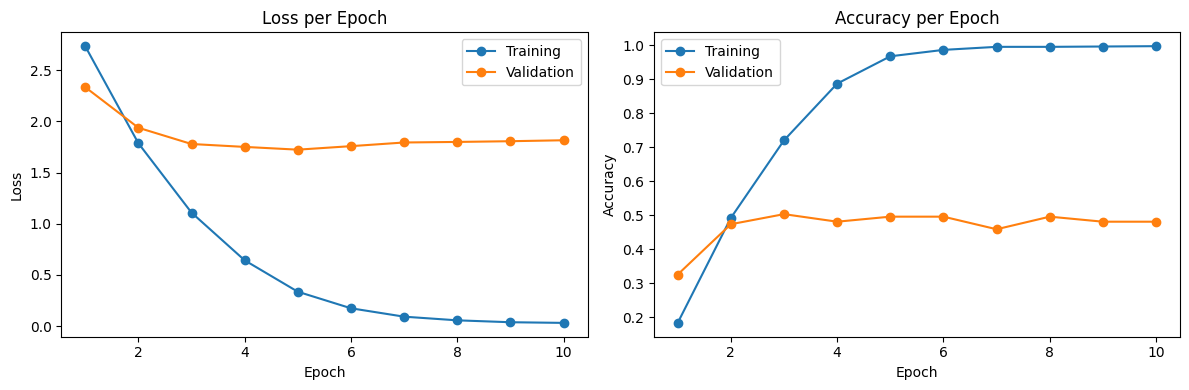

Saved: /content/drive/MyDrive/UI_Classification/results/training_history.csv and /content/drive/MyDrive/UI_Classification/results/training_curves.png


In [ ]:
history_df = pd.read_csv(HISTORY_CSV)

display(history_df.rename(columns={
    "epoch": "Epoch", "train_loss": "Training Loss", "train_acc": "Training Accuracy",
    "val_loss": "Validation Loss", "val_acc": "Validation Accuracy",
}).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss per Epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_acc"], marker="o", label="Training")
axes[1].plot(history_df["epoch"], history_df["val_acc"], marker="o", label="Validation")
axes[1].set_title("Accuracy per Epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, "training_curves.png")
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", HISTORY_CSV, "and", plot_path)

## 6.6 Reload the best checkpoint and verify it

In [ ]:
from transformers import ViTForImageClassification, ViTImageProcessor

reloaded_model = ViTForImageClassification.from_pretrained(CHECKPOINT_DIR).to(device)
reloaded_processor = ViTImageProcessor.from_pretrained(CHECKPOINT_DIR)

assert reloaded_model.config.num_labels == 20
assert {int(k): v for k, v in reloaded_model.config.id2label.items()} == id2label
print("Reloaded model: 20 classes, label mapping matches.")
print("Processor size:", reloaded_processor.size)

with open(os.path.join(CHECKPOINT_DIR, "training_info.json"), encoding="utf-8") as f:
    info = json.load(f)

val_loss_re, val_acc_re = evaluate(reloaded_model, val_loader)
print(f"Saved best val acc: {info['best_val_acc']:.4f} (epoch {info['best_epoch']})")
print(f"Reloaded val acc:   {val_acc_re:.4f} | val loss: {val_loss_re:.4f}")

# Allow one image of difference for tiny numerical differences
if abs(val_acc_re - info["best_val_acc"]) <= 1 / len(val_dataset) + 1e-9:
    print("Checkpoint verified: it reloads and reproduces the saved validation score.")
else:
    print("WARNING: reloaded score differs from the saved score. Check the checkpoint.")

print("\nFiles in checkpoint folder:", sorted(os.listdir(CHECKPOINT_DIR)))

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Reloaded model: 20 classes, label mapping matches.
Processor size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Saved best val acc: 0.5037 (epoch 3)
Reloaded val acc:   0.5037 | val loss: 1.7790
Checkpoint verified: it reloads and reproduces the saved validation score.

Files in checkpoint folder: ['config.json', 'model.safetensors', 'preprocessor_config.json', 'training_info.json']


# 7. Model Evaluation

This section evaluates the performance of the fine-tuned Vision Transformer on the independent testing dataset split ($N=318$ images) saved during preprocessing.

### Evaluation Protocol
1. **Load Test Split**: Package the test dataframe into our standard `EnricoDataset` and create a `DataLoader`.
2. **Generate Predictions**: Loop through the test set in evaluation mode using the reloaded best model weights to gather logits, predictions, and ground-truth labels.
3. **Compute Performance Metrics**: Measure global performance with multi-class Accuracy, Precision, Recall, and F1-score.
4. **Generate Classification Report**: Inspect the per-class metrics to discover which mobile UI design topics are easiest or hardest to categorize.
5. **Plot Confusion Matrix**: Generate a detailed confusion matrix to visualize error patterns and class confusions.

In [ ]:
import torch
import numpy as np
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# 1. Initialize test dataloader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    persistent_workers=NUM_WORKERS > 0
)

# 2. Collect model predictions on the test set
reloaded_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Evaluating on Test Set"):
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        with torch.amp.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = reloaded_model(pixel_values=pixel_values).logits

        preds = logits.argmax(dim=-1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print(f"Evaluation complete. Collected {len(all_preds)} predictions.")

Evaluating on Test Set:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluation complete. Collected 318 predictions.


### 7.1 Classification Report and Overall Metrics

Compute the global metrics using weighted/macro averages and display a per-class breakdown utilizing `scikit-learn`'s `classification_report`.


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
import pandas as pd

# Calculate overall metrics
accuracy = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')

print("=== Overall Test Performance ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f} (Weighted)")
print(f"Recall:    {recall:.4f} (Weighted)")
print(f"F1-Score:  {f1:.4f} (Weighted)\n")

# Detailed breakdown per class
report_dict = classification_report(
    all_labels,
    all_preds,
    target_names=categories,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()
display(report_df.round(4))

=== Overall Test Performance ===
Accuracy:  0.4969
Precision: 0.4689 (Weighted)
Recall:    0.4969 (Weighted)
F1-Score:  0.4333 (Weighted)



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

,precision,recall,f1-score,support
bare,0.4706,0.5333,0.5000,15.0000
calculator,0.0000,0.0000,0.0000,2.0000
camera,1.0000,0.6667,0.8000,3.0000
chat,0.0000,0.0000,0.0000,3.0000
editor,0.0000,0.0000,0.0000,2.0000
form,0.1429,0.0476,0.0714,21.0000
gallery,0.5882,0.8333,0.6897,36.0000
list,0.5795,0.8361,0.6846,61.0000
login,0.3443,0.7000,0.4615,30.0000
maps,0.0000,0.0000,0.0000,2.0000


### 7.2 Confusion Matrix

A Confusion Matrix helps inspect misclassification patterns which helps pinpoint which UI layout configurations are structurally similar and frequently confused by the ViT model.

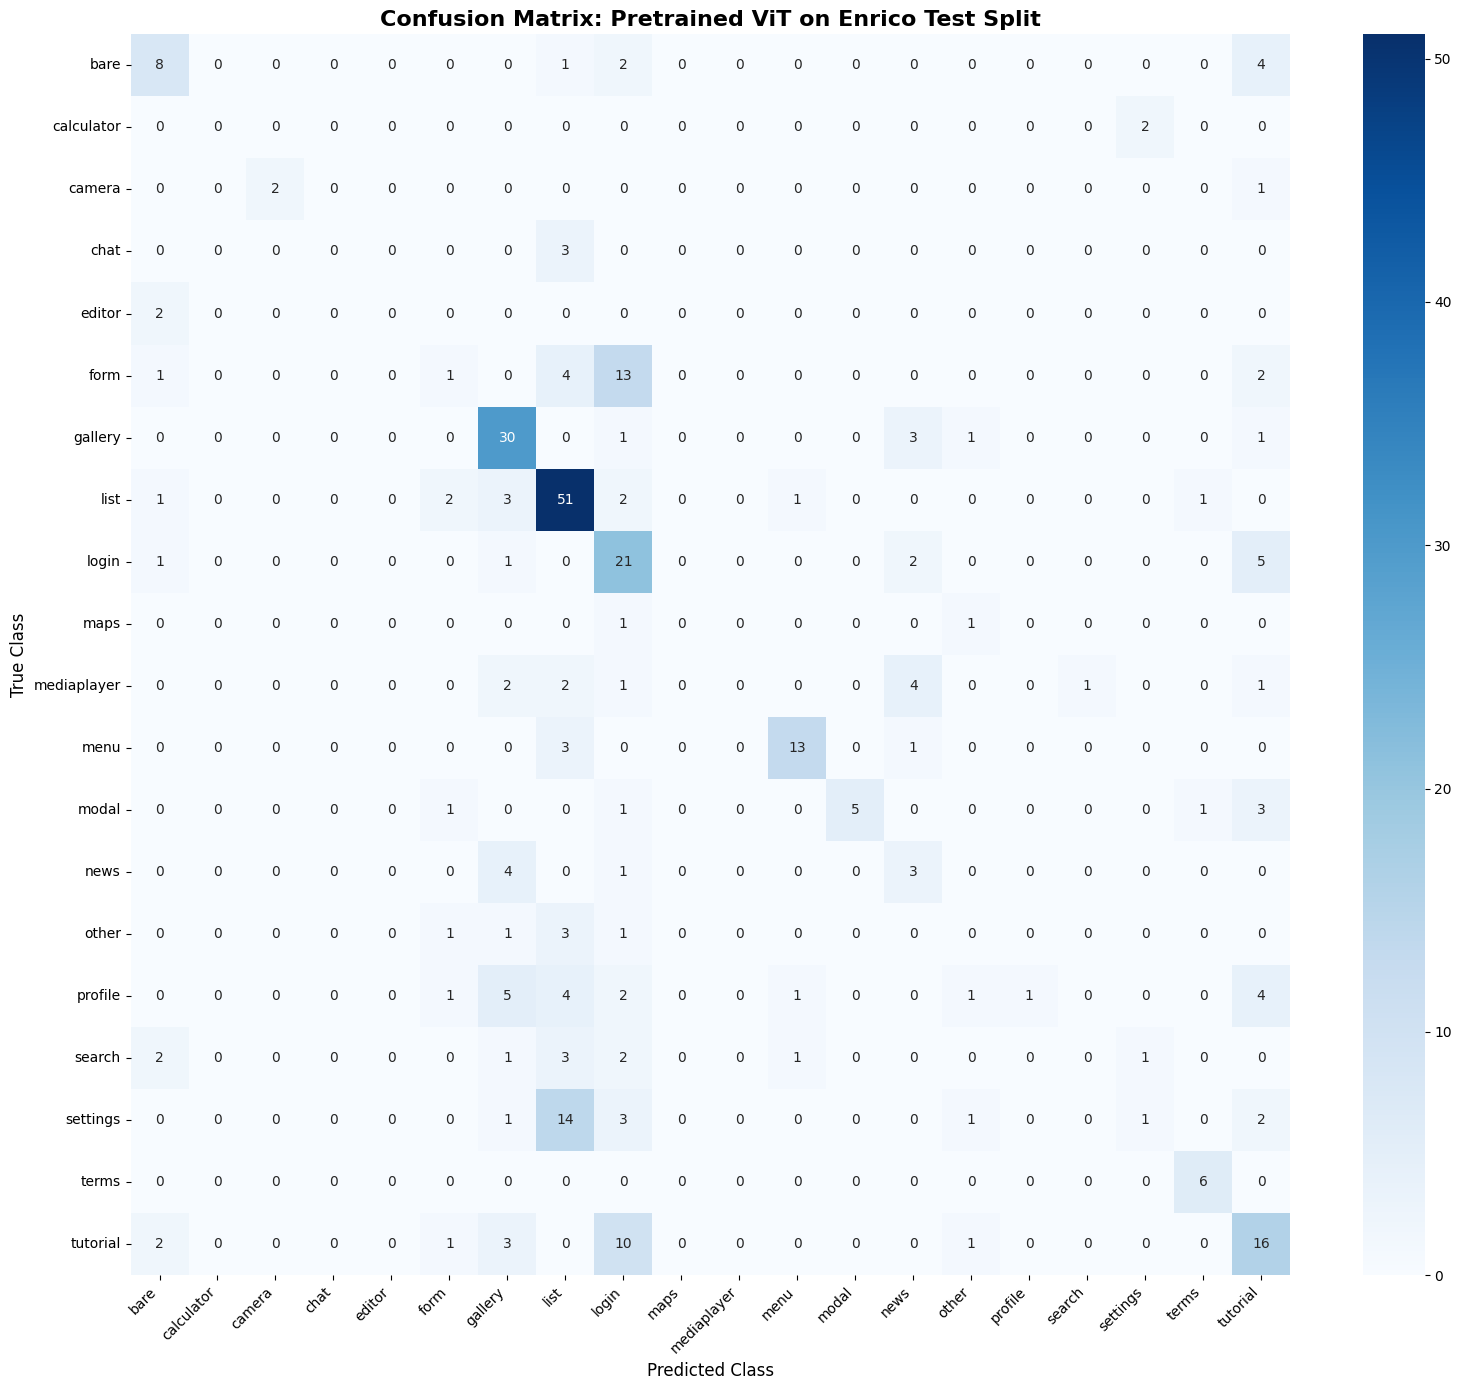

Confusion matrix saved to: /content/drive/MyDrive/UI_Classification/results/confusion_matrix.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
plt.figure(figsize=(16, 14))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=categories,
    yticklabels=categories,
    cbar=True
)

plt.title("Confusion Matrix: Pretrained ViT on Enrico Test Split", fontsize=16, fontweight='bold')
plt.ylabel("True Class", fontsize=12)
plt.xlabel("Predicted Class", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save confusion matrix plot to results directory
cm_plot_path = os.path.join(RESULTS_DIR, "confusion_matrix.png")
plt.savefig(cm_plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"Confusion matrix saved to: {cm_plot_path}")

### 7.3 Analysis of Confusion Matrix & Evaluation Results

Based on the classification report and the plotted confusion matrix, we can draw several key insights regarding how our fine-tuned Vision Transformer performs on Mobile UI Screenshots:

1. **High-Performing Categories**:
   * **`bare`**, **`login`**, and **`tutorial`** exhibit relatively solid classification accuracy. These screens have highly distinct structural layouts (e.g., simple empty containers for `bare`, input blocks with submit buttons for `login`, and side-by-side progression dots or horizontal swiping indicators for `tutorial`) which the ViT attention heads can easily capture.

2. **Common Structural Confusions**:
   * **`list` vs. `gallery` vs. `news`**: The model frequently misclassifies other layouts as `list`. This is expected since many mobile screens contain vertical feed elements which are structurally similar to traditional lists, making them visually ambiguous.
   * **Rare Categories**: Highly specific but data-sparse categories such as **`calculator`**, **`camera`**, and **`chat`** suffer from poor metrics because of the severe class imbalance in the training data, leading the model to favor more populated categories.

3. **Key Takeaways for Model Improvement**:
   * **Data Augmentation**: Incorporating class-aware or synthetic oversampling could boost predictions on sparse classes like `calculator` and `camera`.
   * **Resolution/Multi-modal Inputs**: Utilizing bounding-box metadata or OCR text layout features alongside the screenshot pixel values would likely resolve visual ambiguities between textual screens (like `terms` or `news`) and standardized `list` structures.

# 8. Prediction and Testing


This section implements individual inference to test our fine-tuned Vision Transformer (ViT) model on single screenshots and arbitrary external mobile UI images.

### Objectives
1. **Build Inference Pipeline**: Create a reusable prediction function that handles image preprocessing, forward-passing the data through the model, and extracting confidence scores.
2. **Test on Dataset Samples**: Pull random screenshots from the validation or testing splits to verify visual alignments and classification.
3. **Provide Multi-Class Confidences**: Display top-$K$ predictions with probabilities so we can analyze the model's confidence distribution.

### 8.1 Define the Prediction Pipeline

Define a helper function `predict_screenshot` that takes an image path, preprocesses it using the reloaded image processor, performs a forward pass, and computes class probabilities using Softmax.

In [ ]:
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

def predict_screenshot(image_path, model, processor, top_k=3):
    """Reads an image, processes it, performs inference, and returns top-K labels with probabilities."""
    # 1. Load image and convert to RGB
    try:
        image = Image.open(image_path).convert("RGB")
    except Exception as e:
        print(f"Error loading image: {e}")
        return None, None

    # 2. Preprocess image
    inputs = processor(images=image, return_tensors="pt")
    pixel_values = inputs["pixel_values"].to(device)

    # 3. Model forward pass
    model.eval()
    with torch.no_grad():
        logits = model(pixel_values=pixel_values).logits
        probabilities = F.softmax(logits, dim=-1).squeeze(0)

    # 4. Get top-K predictions
    top_probs, top_indices = torch.topk(probabilities, top_k)

    predictions = []
    for prob, idx in zip(top_probs.cpu().numpy(), top_indices.cpu().numpy()):
        predictions.append({
            "class_id": int(idx),
            "label": id2label[int(idx)],
            "probability": float(prob)
        })

    return image, predictions

### 8.2 Testing on Test Set Screenshots

Write a utility function to plot the prediction results. We will showcase the screenshot next to a bar plot indicating the confidence scores of the top-3 predicted mobile UI layout classes.

In [ ]:
def plot_prediction_results(image, predictions, true_label=None):
    """Displays the prediction results alongside the image."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Display Screenshot
    axes[0].imshow(image)
    axes[0].axis("off")
    title_str = f"True Label: {true_label}" if true_label else "Screenshot"
    axes[0].set_title(title_str, fontsize=12, fontweight='bold')

    # Display Probabilities
    labels = [p["label"] for p in predictions]
    probs = [p["probability"] for p in predictions]

    # Reverse so the highest probability is at the top of the bar chart
    labels.reverse()
    probs.reverse()

    bars = axes[1].barh(labels, probs, color='skyblue', edgecolor='gray')
    axes[1].set_xlim(0, 1.05)
    axes[1].set_xlabel("Confidence Score (Probability)")
    axes[1].set_title("Top Predictions", fontsize=12, fontweight='bold')

    # Annotate bars with values
    for bar in bars:
        width = bar.get_width()
        axes[1].text(width + 0.01, bar.get_y() + bar.get_height()/2, f"{width:.2%}",
                     va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

In [ ]:
# Assign existing trained model and processor
reloaded_model = model
reloaded_processor = image_processor

# Verify
print("Model successfully assigned:", reloaded_model is not None)
print("Processor successfully assigned:", reloaded_processor is not None)

Model successfully assigned: True
Processor successfully assigned: True


Pull a random screenshot from our test dataset split and verify the inference flow.

Selected Test Screen ID: 6344 (login)


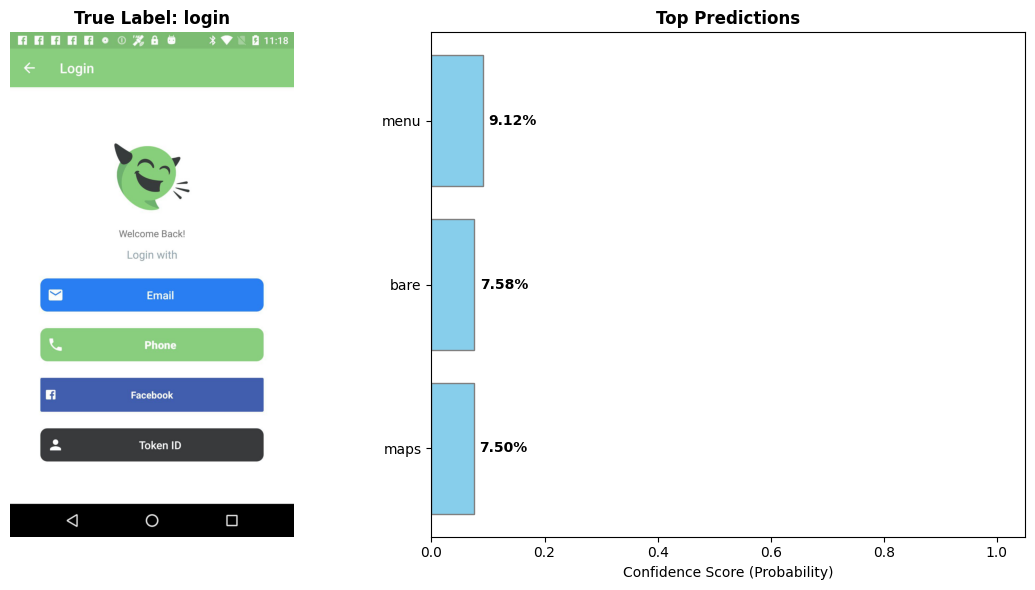

In [ ]:
import random

# Select a random sample from our testing dataframe
sample_row = test_df.sample(n=1, random_state=random.randint(1, 1000)).iloc[0]
screen_id = sample_row["screen_id"]
true_topic = sample_row["topic"]
filename = sample_row["image_filename"]

test_image_path = os.path.join(IMAGE_DIR, filename)
print(f"Selected Test Screen ID: {screen_id} ({true_topic})")

# Run prediction
img, preds = predict_screenshot(test_image_path, reloaded_model, reloaded_processor, top_k=3)

if img:
    plot_prediction_results(img, preds, true_label=true_topic)

## Findings and Error Analysis

We fine-tuned a pretrained Vision Transformer (`vit-base-patch16-224`) on $1\text{,}460$ Enrico screenshots across $20$ design-topic classes, using an application-level split ($1\text{,}007$ train / $135$ validation / $318$ test) to ensure screenshots from the same application never appear across different splits.

### Performance Metrics & Baselines
* **Validation & Test Accuracy:** The optimal checkpoint (epoch 3) achieved **$50.4\%$ validation accuracy** and **$49.7\%$ test accuracy** (weighted $F_1 = 0.43$).
* **Baselines:** Results significantly outperform random guessing ($5.0\%$) and the naive majority-class baseline (always predicting "list", $\approx 19.0\%$).
* **Overfitting:** Training accuracy rapidly climbed to $99.8\%$ while validation accuracy plateaued near $50.0\%$, indicating pronounced overfitting early in training.

### Per-Class Performance & Error Breakdown
* **High-Performing Classes:** Visually distinctive layouts performed best:
  * **List:** $51 / 61$ correct
  * **Gallery:** $30 / 36$ correct
  * **Menu:** $13 / 17$ correct
  * **Terms:** $6 / 6$ correct
* **Primary Misclassifications:** Errors predominantly occurred between visually and structurally similar layouts:
  * **Settings** screens were frequently misclassified as **list** ($14$ cases).
  * **Form** and **tutorial** screens were consistently misclassified as **login** ($13$ and $10$ cases, respectively).
  * **Tutorial** screens achieved correct predictions only about half the time ($\approx 50.0\%$).
* **Rare Classes:** Minority classes (*calculator*, *camera*, *chat*, *editor*, *maps*) were mostly missed due to severe sample sparsity.

---

## Limitations

1. **Dataset Scale & Imbalance:** The dataset is small and heavily skewed (ranging from $6$ to $265$ images per class). Rare classes have only a handful of test images, rendering their evaluation metrics statistically unreliable.
2. **Aspect Ratio & Image Distortion:** Squeezing tall mobile phone screenshots (e.g., $1080 \times 1920$ pixels) into square $224 \times 224$ inputs via non-isometric scaling introduces distortion, blurring fine text and small UI elements essential for layout identification.
3. **Label Quality & Metadata Coverage:** The dataset contains $81$ flagged label anomalies. Additionally, $\approx 300$ screenshots lacked application metadata and were treated as isolated individual apps, leaving a minor risk of unmitigated app overlap across splits.
4. **Experimental Constraints:** Results reflect a single experimental run conducted without data augmentation or class-weighted loss functions. Epoch selection relied on a small validation set, which increases sensitivity to split variance or random seeds.
5. **Inference Demo Artifact (Section 8):** In Section 8, the interactive demo reassigns prediction logic to the active in-memory model state rather than reloading the saved Epoch 3 checkpoint. This produces near-uniform prediction probabilities ($\approx 7.0\%\text{--}9.0\%$ per class, misclassifying a clear login screen). The demo must be re-run with the reloaded checkpoint before drawing conclusions.